In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# download the VADER lexicon for sentiment analysis
nltk.download("vader_lexicon")

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/yunzhizhang/nltk_data...


True

In [2]:
# Read cleaned data
df = pd.read_json("../data/wildchat_cleaned.json")
print("Conversations:", len(df))

Conversations: 2263


In [3]:
sia = SentimentIntensityAnalyzer()

# compound is VADER's overall score: -1 = most negative, 0 = neutral, +1 = most positive
def vader_score(text):
    return sia.polarity_scores(text)["compound"]

df["first_score"] = df["first_message"].apply(vader_score)
df["last_score"] = df["last_message"].apply(vader_score)

# Change: a negative value means the last message is more negative than the first
df["change"] = df["last_score"] - df["first_score"]

df[["first_score", "last_score", "change"]].describe()

,first_score,last_score,change
count,2263.000000,2263.000000,2263.000000
mean,0.233059,0.156510,-0.076549
std,0.477567,0.405644,0.535937
min,-0.999700,-0.999300,-1.980100
25%,0.000000,0.000000,-0.361200
50%,0.000000,0.000000,0.000000
75%,0.636900,0.421500,0.128600
max,1.000000,0.999900,1.921600


In [5]:
# Group conversations by the number of user messages: 2, 3–5, or 6+
def length_group(n):
    if n == 2:
        return "2"
    elif n <= 5:
        return "3–5"
    else:
        return "6+"

df["length_group"] = df["user_message_count"].apply(length_group)
df["length_group"].value_counts()

length_group
2      893
3–5    864
6+     506
Name: count, dtype: int64

In [6]:
# Summarize each group: size, mean first and last scores, mean change, and share that became more negative
order = ["2", "3–5", "6+"]

summary = df.groupby("length_group").agg(
    n=("change", "size"),
    first_mean=("first_score", "mean"),
    last_mean=("last_score", "mean"),
    mean_change=("change", "mean"),
    share_more_negative=("change", lambda x: (x < 0).mean()),
).reindex(order).round(3)

summary

,n,first_mean,last_mean,mean_change,share_more_negative
length_group,,,,,
2,893,0.217,0.161,-0.056,0.359
3–5,864,0.247,0.161,-0.086,0.424
6+,506,0.237,0.141,-0.096,0.457


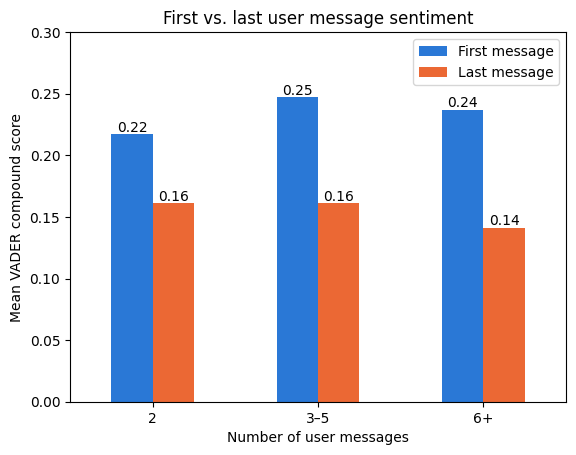

In [11]:
# Plot mean first and last scores for each group
summary[["first_mean", "last_mean"]].plot(kind="bar", rot=0, color=["#2a78d6", "#eb6834"])

plt.xlabel("Number of user messages")
plt.ylabel("Mean VADER compound score")
plt.title("First vs. last user message sentiment")
plt.legend(["First message", "Last message"])
plt.ylim(0, 0.3)

for bars in plt.gca().containers:
    plt.bar_label(bars, fmt="%.2f")

plt.savefig("vader_first_last_by_length.png", dpi=200, bbox_inches="tight")
plt.show()